In [6]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from torch.utils.data import random_split

transform = transforms.ToTensor()

train_full = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    train_full,
    [50000, 10000],
    generator=generator
)

print("MNIST veri seti başarıyla yüklendi")
print("Train görüntüleri:", len(train_dataset))
print("Validation görüntüleri:", len(val_dataset))
print("Test görüntüleri:", len(test_dataset))
print("Görüntü boyutu:", train_full[0][0].shape)

100%|██████████| 9.91M/9.91M [00:00<00:00, 57.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.80MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.4MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.76MB/s]

MNIST veri seti başarıyla yüklendi
Train görüntüleri: 50000
Validation görüntüleri: 10000
Test görüntüleri: 10000
Görüntü boyutu: torch.Size([1, 28, 28])


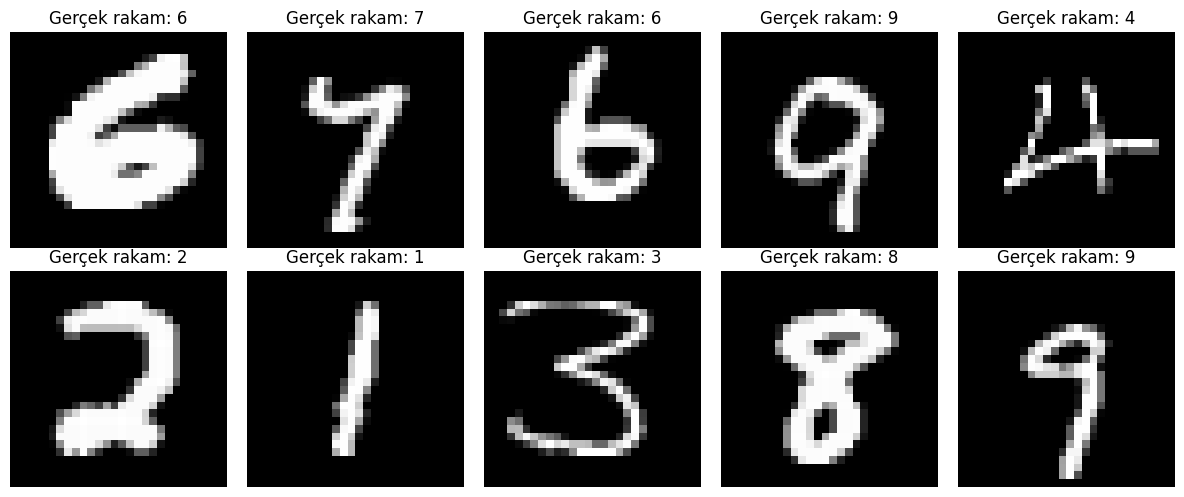

In [7]:

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Gerçek rakam: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
import torch.nn as nn

class MLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


model = MLP()

print(model)

total_params = sum(p.numel() for p in model.parameters())

print("\nToplam parametre sayısı:", total_params)

MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

Toplam parametre sayısı: 235146


In [9]:
import time
import copy
import numpy as np
import random
from torch.utils.data import DataLoader

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

BATCH_SIZE = 128
EPOCHS = 10
LEARNING_RATE = 0.001

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Eğitim ayarları hazır")
print("Cihaz:", device)
print("Batch size:", BATCH_SIZE)
print("Epoch:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Optimizer: Adam")
print("Loss function: CrossEntropyLoss")

Eğitim ayarları hazır
Cihaz: cpu
Batch size: 128
Epoch: 10
Learning rate: 0.001
Optimizer: Adam
Loss function: CrossEntropyLoss


In [10]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = 100.0 * correct / total

    return average_loss, accuracy


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = 100.0 * correct / total

    return average_loss, accuracy


print("Eğitim ve değerlendirme fonksiyonları hazır")

Eğitim ve değerlendirme fonksiyonları hazır


In [11]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

start_time = time.perf_counter()

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2f}% | "
        f"Val Accuracy: {val_acc:.2f}%"
    )

training_time = time.perf_counter() - start_time

print("\nEĞİTİM TAMAMLANDI")
print(f"Toplam eğitim süresi: {training_time:.2f} saniye")

Epoch [1/10] | Train Loss: 0.3755 | Val Loss: 0.1951 | Train Accuracy: 89.63% | Val Accuracy: 94.38%
Epoch [2/10] | Train Loss: 0.1445 | Val Loss: 0.1427 | Train Accuracy: 95.80% | Val Accuracy: 95.74%
Epoch [3/10] | Train Loss: 0.0975 | Val Loss: 0.1072 | Train Accuracy: 97.07% | Val Accuracy: 96.72%
Epoch [4/10] | Train Loss: 0.0694 | Val Loss: 0.1111 | Train Accuracy: 97.91% | Val Accuracy: 96.64%
Epoch [5/10] | Train Loss: 0.0531 | Val Loss: 0.0952 | Train Accuracy: 98.34% | Val Accuracy: 97.16%
Epoch [6/10] | Train Loss: 0.0416 | Val Loss: 0.1000 | Train Accuracy: 98.72% | Val Accuracy: 96.96%
Epoch [7/10] | Train Loss: 0.0324 | Val Loss: 0.0871 | Train Accuracy: 98.99% | Val Accuracy: 97.42%
Epoch [8/10] | Train Loss: 0.0248 | Val Loss: 0.0910 | Train Accuracy: 99.21% | Val Accuracy: 97.50%
Epoch [9/10] | Train Loss: 0.0210 | Val Loss: 0.0888 | Train Accuracy: 99.37% | Val Accuracy: 97.54%
Epoch [10/10] | Train Loss: 0.0154 | Val Loss: 0.0988 | Train Accuracy: 99.55% | Val Accura

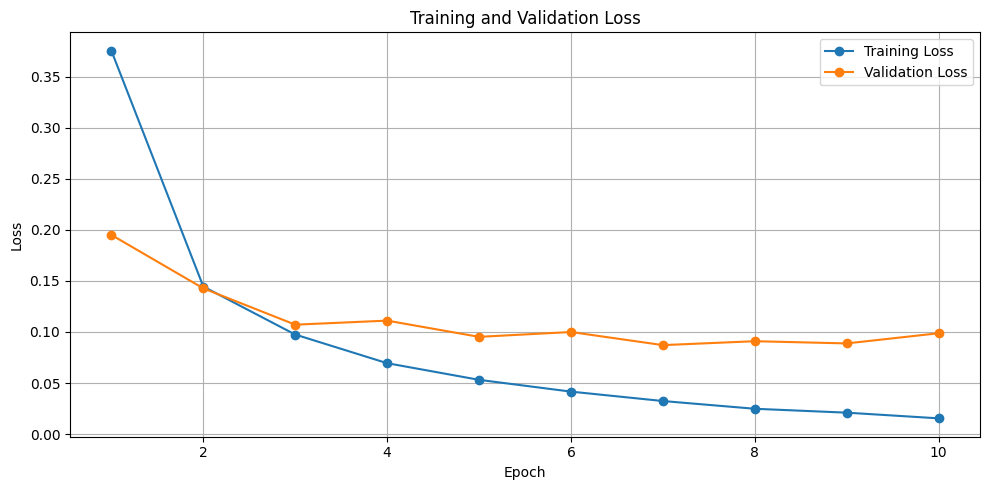

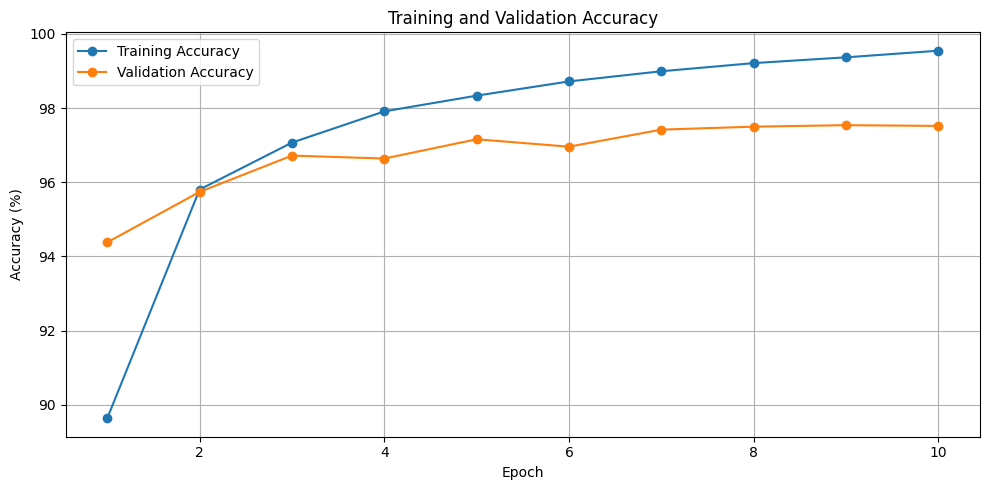

In [12]:

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs_range, history["train_loss"], marker="o",
         label="Training Loss")

plt.plot(epochs_range, history["val_loss"], marker="o",
         label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(epochs_range, history["train_acc"], marker="o",
         label="Training Accuracy")

plt.plot(epochs_range, history["val_acc"], marker="o",
         label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
test_loss, test_acc = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print("===== TEST SONUÇLARI =====")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Eğitim süresi: {training_time:.2f} saniye")
print(f"Son Training Loss: {history['train_loss'][-1]:.4f}")
print(f"Son Validation Loss: {history['val_loss'][-1]:.4f}")
print(f"Son Training Accuracy: {history['train_acc'][-1]:.2f}%")
print(f"Son Validation Accuracy: {history['val_acc'][-1]:.2f}%")

===== TEST SONUÇLARI =====
Test Loss: 0.0791
Test Accuracy: 97.85%
Eğitim süresi: 96.48 saniye
Son Training Loss: 0.0154
Son Validation Loss: 0.0988
Son Training Accuracy: 99.55%
Son Validation Accuracy: 97.52%


In [14]:

class MLP_Small(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


model_small = MLP_Small().to(device)

criterion_small = nn.CrossEntropyLoss()

optimizer_small = torch.optim.Adam(
    model_small.parameters(),
    lr=LEARNING_RATE
)

history_small = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

start_time_small = time.perf_counter()

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model_small,
        train_loader,
        criterion_small,
        optimizer_small,
        device
    )

    val_loss, val_acc = evaluate(
        model_small,
        val_loader,
        criterion_small,
        device
    )

    history_small["train_loss"].append(train_loss)
    history_small["val_loss"].append(val_loss)
    history_small["train_acc"].append(train_acc)
    history_small["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2f}% | "
        f"Val Accuracy: {val_acc:.2f}%"
    )

training_time_small = time.perf_counter() - start_time_small

print(f"\nİkinci modelin eğitim süresi: {training_time_small:.2f} saniye")

Epoch [1/10] | Train Loss: 0.4605 | Val Loss: 0.2705 | Train Accuracy: 87.15% | Val Accuracy: 91.91%
Epoch [2/10] | Train Loss: 0.1946 | Val Loss: 0.1759 | Train Accuracy: 94.29% | Val Accuracy: 94.86%
Epoch [3/10] | Train Loss: 0.1405 | Val Loss: 0.1449 | Train Accuracy: 95.83% | Val Accuracy: 95.53%
Epoch [4/10] | Train Loss: 0.1064 | Val Loss: 0.1255 | Train Accuracy: 96.81% | Val Accuracy: 96.33%
Epoch [5/10] | Train Loss: 0.0852 | Val Loss: 0.1056 | Train Accuracy: 97.38% | Val Accuracy: 96.93%
Epoch [6/10] | Train Loss: 0.0685 | Val Loss: 0.1104 | Train Accuracy: 97.90% | Val Accuracy: 96.68%
Epoch [7/10] | Train Loss: 0.0557 | Val Loss: 0.0969 | Train Accuracy: 98.32% | Val Accuracy: 97.03%
Epoch [8/10] | Train Loss: 0.0469 | Val Loss: 0.0955 | Train Accuracy: 98.58% | Val Accuracy: 97.23%
Epoch [9/10] | Train Loss: 0.0380 | Val Loss: 0.1036 | Train Accuracy: 98.83% | Val Accuracy: 96.91%
Epoch [10/10] | Train Loss: 0.0327 | Val Loss: 0.0968 | Train Accuracy: 99.00% | Val Accura

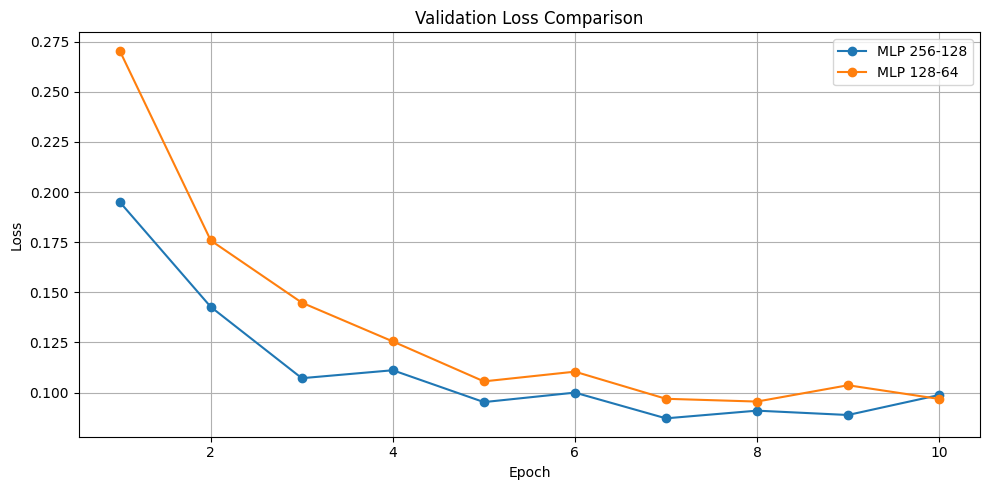

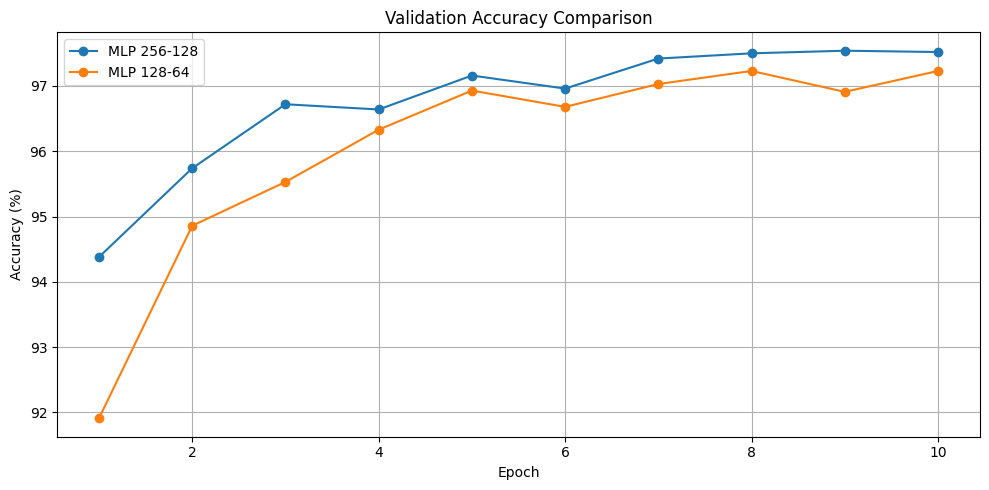

In [15]:

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    history["val_loss"],
    marker="o",
    label="MLP 256-128"
)

plt.plot(
    epochs_range,
    history_small["val_loss"],
    marker="o",
    label="MLP 128-64"
)

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    history["val_acc"],
    marker="o",
    label="MLP 256-128"
)

plt.plot(
    epochs_range,
    history_small["val_acc"],
    marker="o",
    label="MLP 128-64"
)

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Saving unnamed1.jpg to unnamed1.jpg
Fotoğraf boyutu: (2230, 556)


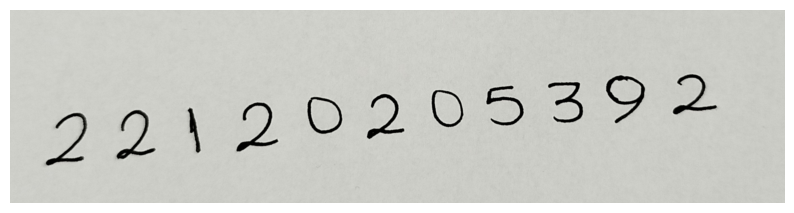

In [16]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

uploaded = files.upload()

filename = next(iter(uploaded))
photo = Image.open(filename).convert("RGB")

print("Fotoğraf boyutu:", photo.size)

plt.figure(figsize=(10, 6))
plt.imshow(photo)
plt.axis("off")
plt.show()

Tahmin edilen öğrenci numarası: 22120205392
Bulunan rakam sayısı: 11


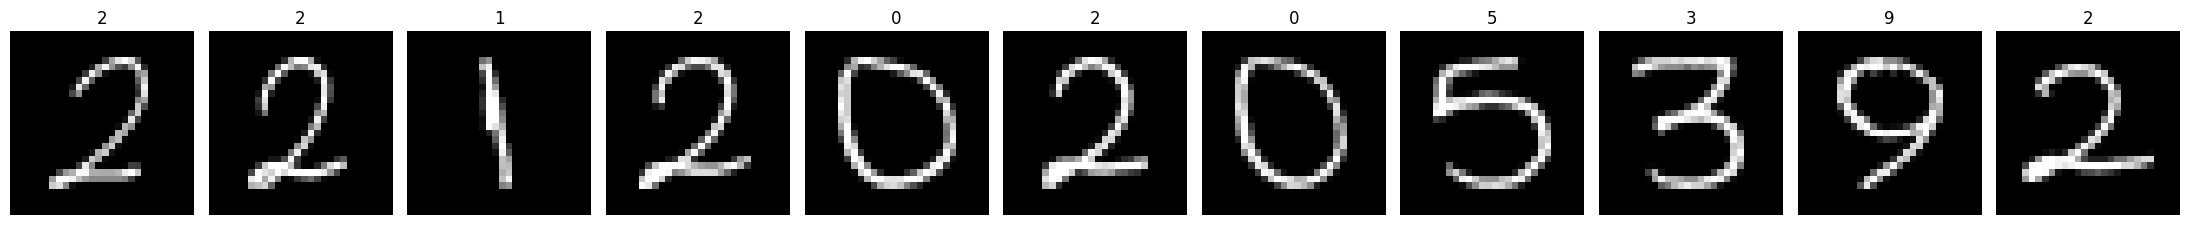

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image

image_path = filename
image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(
        "unnamed.jpg bulunamadı. Dosyayı yeniden yükleyin."
    )

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

_, binary = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

coords = cv2.findNonZero(binary)

if coords is None:
    raise ValueError("Görüntüde rakam bulunamadı.")

x, y, w, h = cv2.boundingRect(coords)

cropped = binary[y:y+h, x:x+w]

column_sums = np.sum(cropped > 0, axis=0)

active = column_sums > 0
segments = []
start = None

for i, value in enumerate(active):
    if value and start is None:
        start = i
    elif not value and start is not None:
        if i - start >= 2:
            segments.append((start, i))
        start = None

if start is not None and len(active) - start >= 2:
    segments.append((start, len(active)))

device = next(model.parameters()).device
predictions = []
processed_images = []

for start, end in segments:
    digit = cropped[:, start:end]

    points = cv2.findNonZero(digit)
    if points is None:
        continue

    dx, dy, dw, dh = cv2.boundingRect(points)
    digit = digit[dy:dy+dh, dx:dx+dw]

    scale = 20.0 / max(digit.shape)
    new_w = max(1, int(digit.shape[1] * scale))
    new_h = max(1, int(digit.shape[0] * scale))

    resized = cv2.resize(
        digit, (new_w, new_h), interpolation=cv2.INTER_AREA
    )

    canvas = np.zeros((28, 28), dtype=np.uint8)
    x_offset = (28 - new_w) // 2
    y_offset = (28 - new_h) // 2

    canvas[y_offset:y_offset+new_h,
           x_offset:x_offset+new_w] = resized

    tensor = torch.tensor(
        canvas, dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0) / 255.0

    model.eval()
    with torch.no_grad():
        output = model(tensor.to(device))
        prediction = output.argmax(dim=1).item()

    predictions.append(str(prediction))
    processed_images.append(canvas)

print("Tahmin edilen öğrenci numarası:", "".join(predictions))
print("Bulunan rakam sayısı:", len(predictions))

if processed_images:
    fig, axes = plt.subplots(
        1, len(processed_images),
        figsize=(2 * len(processed_images), 3)
    )

    if len(processed_images) == 1:
        axes = [axes]

    for i, ax in enumerate(axes):
        ax.imshow(processed_images[i], cmap="gray")
        ax.set_title(predictions[i])
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [18]:

test_loss_small, test_acc_small = evaluate(
    model_small,
    test_loader,
    criterion_small,
    device
)

params_small = sum(
    p.numel() for p in model_small.parameters()
)

print("=" * 40)
print("İKİNCİ MODEL - TEST SONUÇLARI")
print("=" * 40)

print(f"Test Loss: {test_loss_small:.4f}")
print(f"Test Accuracy: {test_acc_small:.2f}%")
print(f"Eğitim süresi: {training_time_small:.2f} saniye")
print(f"Parametre sayısı: {params_small}")
print(f"Son Training Loss: {history_small['train_loss'][-1]:.4f}")
print(f"Son Validation Loss: {history_small['val_loss'][-1]:.4f}")
print(f"Son Training Accuracy: {history_small['train_acc'][-1]:.2f}%")
print(f"Son Validation Accuracy: {history_small['val_acc'][-1]:.2f}%")

İKİNCİ MODEL - TEST SONUÇLARI
Test Loss: 0.0821
Test Accuracy: 97.66%
Eğitim süresi: 86.91 saniye
Parametre sayısı: 109386
Son Training Loss: 0.0327
Son Validation Loss: 0.0968
Son Training Accuracy: 99.00%
Son Validation Accuracy: 97.23%
